In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

import numpy as np

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    ds_djf['time'] = pd.date_range(str(ds_djf.time[0].values).split('-')[0], str(int(str(ds_djf.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')
    return ds_djf


def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')


def load_climatology(path):
    clim = xr.open_dataset(glob.glob(path)[0])
    clim['time'] = [1,2,3,4,5,6,7,8,9,10,11,12]
    clim = clim.rename({'time': 'month'})
    return clim

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data

def pressure_weighting(data, plevs=slice(7000,2000)):
    # here I select the pressure level intervall 
    # for which I want to caluculate the layer weights
    # (in this case plevs = 70 - 20 hPa)
    data = data.sel(plev=plevs)
    # Then natural logarithm of this pressure values is caluculated
    log_pressure = np.log(data.plev.values)  
    # the difference between this logaritmic pressure values is made
    log_layer_thickness = np.abs(np.diff(log_pressure))
    # then i devide these differences by the total thickness of the layer
    # = sum of the differences
    log_layer_thickness = log_layer_thickness / sum(log_layer_thickness)

    # this part just creates an array to make it compatible with the data 
    # #(no manipulation of the results done in this step)
    log_layer_thickness = xr.DataArray(
        log_layer_thickness,
        coords={"plev": data.plev.values[:-1]},  # Assign to the lower pressure level of each layer
        dims=["plev"]
    )

    # finally I multiply the data with the "normalized" thickness of the pressure layer
    data = data * log_layer_thickness

    return data.sum(dim='plev')

In [2]:

path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/temperature_wind/'

enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])


In [3]:
# calculation for piControl
# for model in models:
#     ua_clim_pi = load_climatology(path_piControl + model + '/ua_clim_AmonZ*')
#     ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')
    
#     ta_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/ta_AmonZ*.nc')[0], decode_times=time_coder)
#     ta_ano = anomaly_calculation(ta_tmp, ta_clim_pi)
#     ta_piControl = calculate_djf_mean(ta_ano)

#     ua_tmp = xr.open_dataset(glob.glob(path_piControl + model + '/ua_AmonZ*.nc')[0], decode_times=time_coder)
#     ua_ano = anomaly_calculation(ua_tmp, ua_clim_pi)
#     ua_piControl = calculate_djf_mean(ua_ano)

#     enso_nao_flags.loc[model,'deltaT_tropics'] = pressure_weighting(ta_piControl.sel(time = enso_nao_flags.loc[model]['year'].values, method='nearest').ta.sel(lat=slice(-20,20)).mean('lat')).squeeze().values
#     enso_nao_flags.loc[model,'deltaT_polar'] = pressure_weighting(ta_piControl.sel(time = enso_nao_flags.loc[model]['year'].values, method='nearest').ta.sel(lat=slice(70,90)).mean('lat')).squeeze().values
#     enso_nao_flags.loc[model,'deltaU'] = ua_piControl.sel(time = enso_nao_flags.loc[model]['year'].values, method='nearest').ua.sel(lat=slice(55,65), plev=1000).mean('lat').squeeze().values
# enso_nao_flags.reset_index().to_csv('/home/kperny/VolMIP_stratosphere/tab/ta_ua_piControl.csv', index=False)

# read pre-calculated table
df_pi_control = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/ta_ua_piControl.csv')
df_pi_control = df_pi_control.set_index(['model', 'realization'])

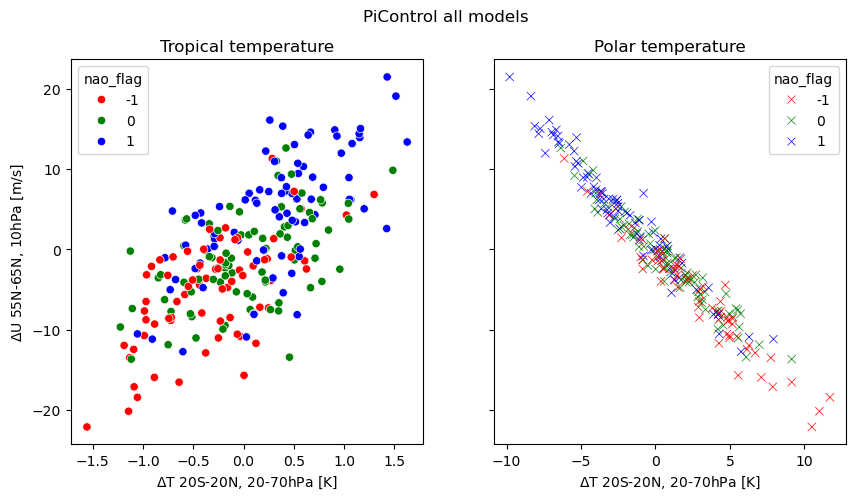

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(10,5), sharey=True)
sns.scatterplot(df_pi_control.reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[0])
sns.scatterplot(df_pi_control.reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='x', ax=axs[1])
plt.suptitle('PiControl all models')
axs[0].set_title('Tropical temperature')
axs[1].set_title('Polar temperature')
axs[0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
axs[0].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
axs[1].set_xlabel('$\Delta$T 70S-90N, 20-70hPa [K]')

plt.savefig(plotdir + 'piControl_allmodels.png', dpi=200)

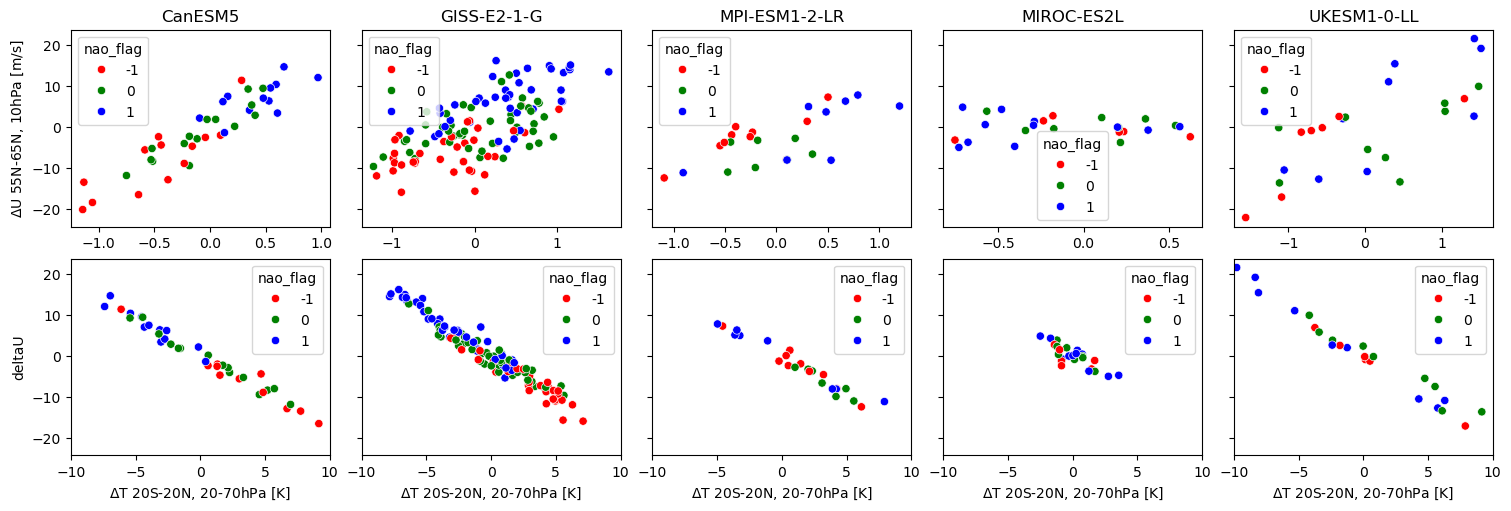

In [5]:
fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

for i, model in enumerate(models):
    sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[0, i])
    #axs[0,i].set_xlim(-1,1)
    axs[0,i].set_xlabel('')
    sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[1, i])
    axs[1,i].set_xlim(-10,10)
    axs[1,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')

    axs[0,i].set_title(model)
axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
plt.savefig(plotdir + 'piControl_individualmodels.png', dpi=200)

In [6]:
df_pi_control = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/ta_ua_piControl.csv')
df_pi_control = df_pi_control.set_index(['model', 'realization'])

In [7]:
volc_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
volc_nao_flags = volc_nao_flags.set_index(['model', 'realization'])
df_volc = volc_nao_flags.where(volc_nao_flags.experiment=='volc').dropna().drop('experiment', axis=1)

# model = models[0]
for model in models:
    ta_volc = load_data(path + model + '/ta_AmonZ_*fixed_dates.nc')
    ua_volc = load_data(path + model + '/ua_AmonZ_*fixed_dates.nc')
    ua_clim_pi = load_climatology(path_piControl + model + '/ua_clim_AmonZ*')
    ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')

    ta_ano = anomaly_calculation(ta_volc['ta'], ta_clim_pi['ta'])
    ta_volc = calculate_djf_mean(ta_ano)

    ua_ano = anomaly_calculation(ua_volc['ua'], ua_clim_pi['ua'])
    ua_volc = calculate_djf_mean(ua_ano)

    df_volc.loc[model,'deltaT_tropics'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(-20,20)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaT_polar'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(70,90)).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values
    df_volc.loc[model,'deltaU'] = ua_volc.sel(time='1992-02').sel(lat=slice(55,65), plev=1000).mean('lat').squeeze().sel(ens=df_volc.loc[model].index).values


/tmp/ipykernel_3708261/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3708261/1070168184.py:27: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  clim = xr.open_dataset(glob.glob(path)[0])
/tmp/ipykernel_3708261/1070168184.py:37: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds.append(x

Text(0, 0.5, '$\\Delta$U 55N-65N, 10hPa [m/s]')

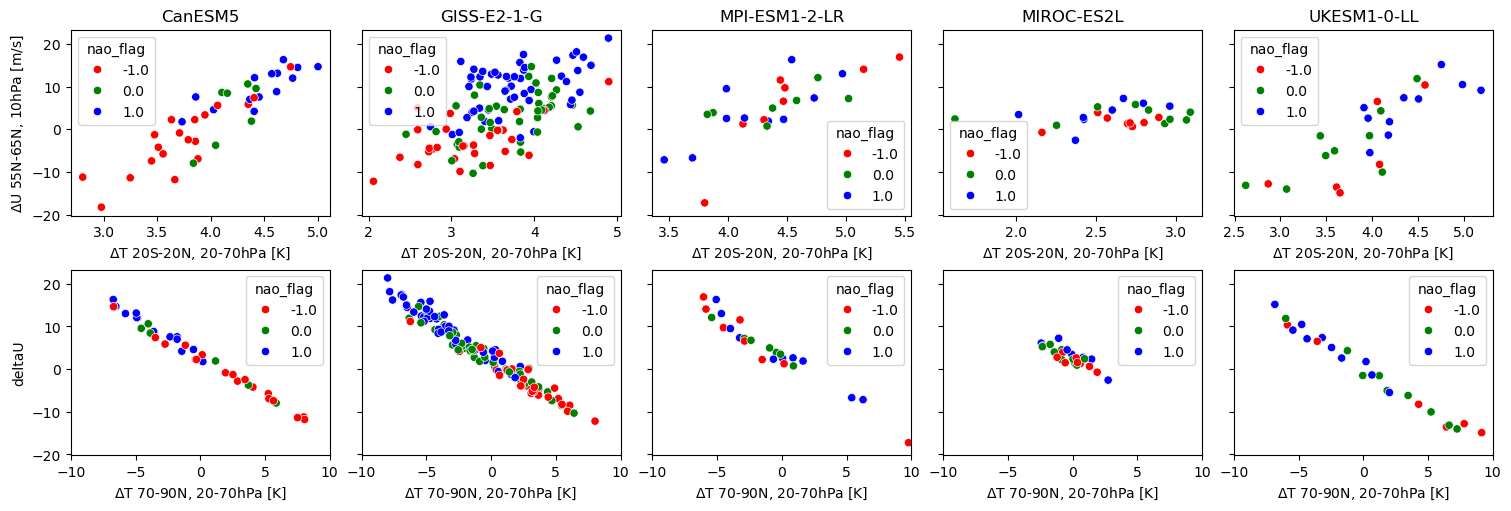

In [8]:
fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

for i, model in enumerate(models):
    sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[0, i])
    #axs[0,i].set_xlim(-1,1)
    axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
    sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[1, i])
    axs[1,i].set_xlim(-10,10)
    axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

    axs[0,i].set_title(model)
axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
#plt.savefig(plotdir + 'piControl_individualmodels.png', dpi=200)

In [9]:
#df_pi_control = df_pi_control.set_index(['model', 'realization'])
df_pi_control['NAO piControl'] = df_pi_control['nao_flag']

df_volc['NAO volcanic'] = df_volc['nao_flag']

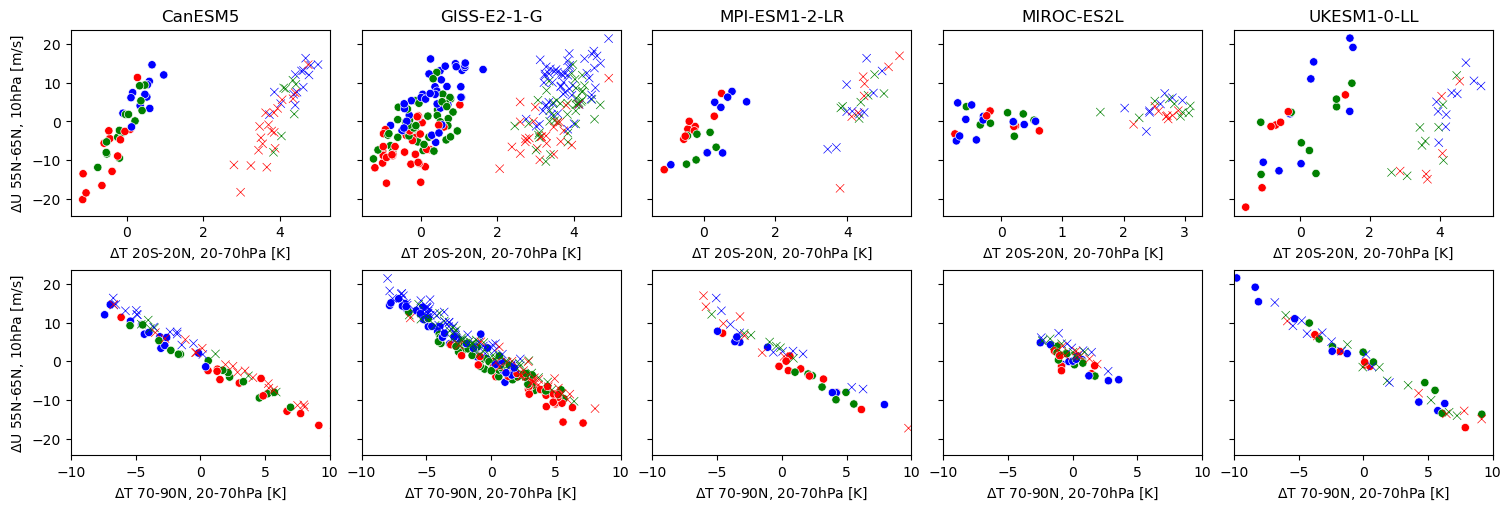

In [10]:
fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

for i, model in enumerate(models):
    c = sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='NAO piControl', palette=['red', 'green', 'blue'], ax=axs[0, i], legend=False)
    d = sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='NAO volcanic', palette=['red', 'green', 'blue'], marker='x', ax=axs[0, i], legend=False)

    axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
    sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='NAO piControl', palette=['red', 'green', 'blue'], ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='NAO volcanic', palette=['red', 'green', 'blue'], marker='x', ax=axs[1, i], legend=False)
    axs[1,i].set_xlim(-10,10)
    axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

    axs[0,i].set_title(model)
axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
axs[1,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')

plt.savefig(plotdir + 'volcVSpiControl_individualmodels.png', dpi=200)

In [11]:
picontrol_nao = volc_nao_flags.where(volc_nao_flags.experiment=='piControl')['nao_flag'].dropna()
volc_nao = volc_nao_flags.where(volc_nao_flags.experiment=='volc')['nao_flag'].dropna()

In [12]:
# df_volc.loc[picontrol_nao == volc_nao, 'change flag'] = df_volc.loc[picontrol_nao == volc_nao]['nao_flag']
# df_volc.loc[(picontrol_nao == 1) & (volc_nao == -1), 'change flag'] = -4
# df_volc.loc[(picontrol_nao == 1) & (volc_nao == 0), 'change flag'] = -3
# df_volc.loc[(picontrol_nao == 0) & (volc_nao == 1), 'change flag'] = -2
# df_volc.loc[(picontrol_nao == 0) & (volc_nao == -1), 'change flag'] = 2
# df_volc.loc[(picontrol_nao == -1) & (volc_nao == 1), 'change flag'] = 3
# df_volc.loc[(picontrol_nao == -1) & (volc_nao == 0), 'change flag'] = 4

# enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
# enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])
# df_volc_clim = enso_nao_flags.where(enso_nao_flags.experiment=='volc').dropna().drop('experiment', axis=1)

# # model = models[0]
# for model in models:
#     ta_volc = load_data(path + model + '/ta_AmonZ_*fixed_dates.nc')
#     ua_volc = load_data(path + model + '/ua_AmonZ_*fixed_dates.nc')
#     ua_clim_pi = load_climatology(path_piControl + model + '/ua_clim_AmonZ*')
#     ta_clim_pi = load_climatology(path_piControl + model + '/ta_clim_AmonZ*')

#     ta_ano = ta_volc.ta - ta_volc.ta.mean('ens')
#     ta_volc = calculate_djf_mean(ta_ano)
    
#     ua_ano = ua_volc.ua - ua_volc.ua.mean('ens')
#     ua_volc = calculate_djf_mean(ua_ano)

#     df_volc_clim.loc[model,'deltaT_tropics'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(-20,20)).mean('lat').squeeze().sel(ens=df_volc_clim.loc[model].index).values
#     df_volc_clim.loc[model,'deltaT_polar'] = pressure_weighting(ta_volc.sel(time='1992-02')).sel(lat=slice(70,90)).mean('lat').squeeze().sel(ens=df_volc_clim.loc[model].index).values
#     try:
#         df_volc_clim.loc[model,'deltaU'] = ua_volc.sel(time='1992-02').sel(lat=slice(55,65), plev=1000).mean('lat').squeeze().sel(ens=df_volc_clim.loc[model].index).values
#     except KeyError: 
#         print(model)

In [13]:
df_volc.loc[picontrol_nao == volc_nao, 'change direction'] = 'stayed'
df_volc.loc[(picontrol_nao == 1) & (volc_nao == -1), 'change direction'] = 'minus'
df_volc.loc[(picontrol_nao == 1) & (volc_nao == 0), 'change direction'] = 'neutral'
df_volc.loc[(picontrol_nao == 0) & (volc_nao == 1), 'change direction'] = "plus"
df_volc.loc[(picontrol_nao == 0) & (volc_nao == -1), 'change direction'] = 'minus'
df_volc.loc[(picontrol_nao == -1) & (volc_nao == 1), 'change direction'] = "plus"
df_volc.loc[(picontrol_nao == -1) & (volc_nao == 0), 'change direction'] = 'neutral'

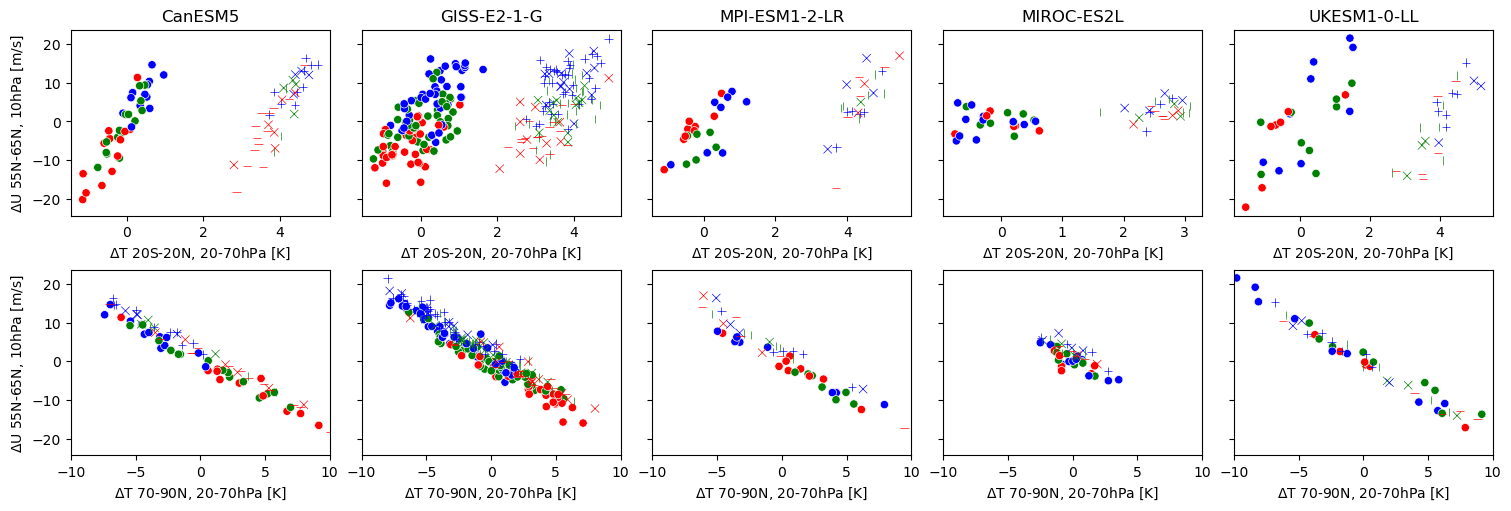

In [14]:
fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

markers = {'stayed': 'x', 'minus': 0, 'plus': '+', 'neutral': '|'}
for i, model in enumerate(models):
    c = sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[0, i], legend=False)
    e = sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], style="change direction", markers=markers, ax=axs[0, i], legend=False)
    # d = sns.scatterplot(df_volc_clim.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='+', ax=axs[0, i], legend=False)

    axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
    sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], style="change direction", markers=markers, ax=axs[1, i], legend=False)
    # sns.scatterplot(df_volc_clim.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='+', ax=axs[1, i], legend=False)
    axs[1,i].set_xlim(-10,10)
    axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

    axs[0,i].set_title(model)
axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
axs[1,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')

plt.savefig(plotdir + 'volcVSpiControl_individualmodels_all.png', dpi=200)

In [15]:
df_volc['nao_flag_picontrol'] = picontrol_nao.values

In [16]:
df_volc.loc[model].reset_index()

,realization,nao,nao_flag,deltaT_tropics,deltaT_polar,deltaU,NAO volcanic,change direction,nao_flag_picontrol
0,r10i1p1f2,0.032280,0.0,4.109179,5.231194,-10.045719,0.0,neutral,-1.0
1,r11i1p1f2,-0.619068,-1.0,4.574869,-5.873640,10.394612,-1.0,minus,1.0
2,r13i1p1f2,1.386235,1.0,4.753318,-6.839155,15.182434,1.0,plus,-1.0
3,r14i1p1f2,-0.184520,0.0,4.093820,-1.233437,4.328900,0.0,neutral,-1.0
4,r15i1p1f2,0.120669,0.0,3.434312,1.233804,-1.542843,0.0,neutral,-1.0
5,r16i1p1f2,-0.741705,-1.0,3.611660,6.415372,-13.569904,-1.0,minus,0.0
6,r17i1p1f2,-0.397071,0.0,2.621603,6.624087,-13.153143,0.0,neutral,1.0
7,r18i1p1f2,0.597092,1.0,4.983490,-4.764138,10.488638,1.0,stayed,1.0
8,r19i1p1f2,1.352160,1.0,4.188035,0.203546,1.766818,1.0,plus,-1.0
9,r1i1p1f2,1.708474,1.0,4.505074,-4.350812,7.123069,1.0,plus,0.0


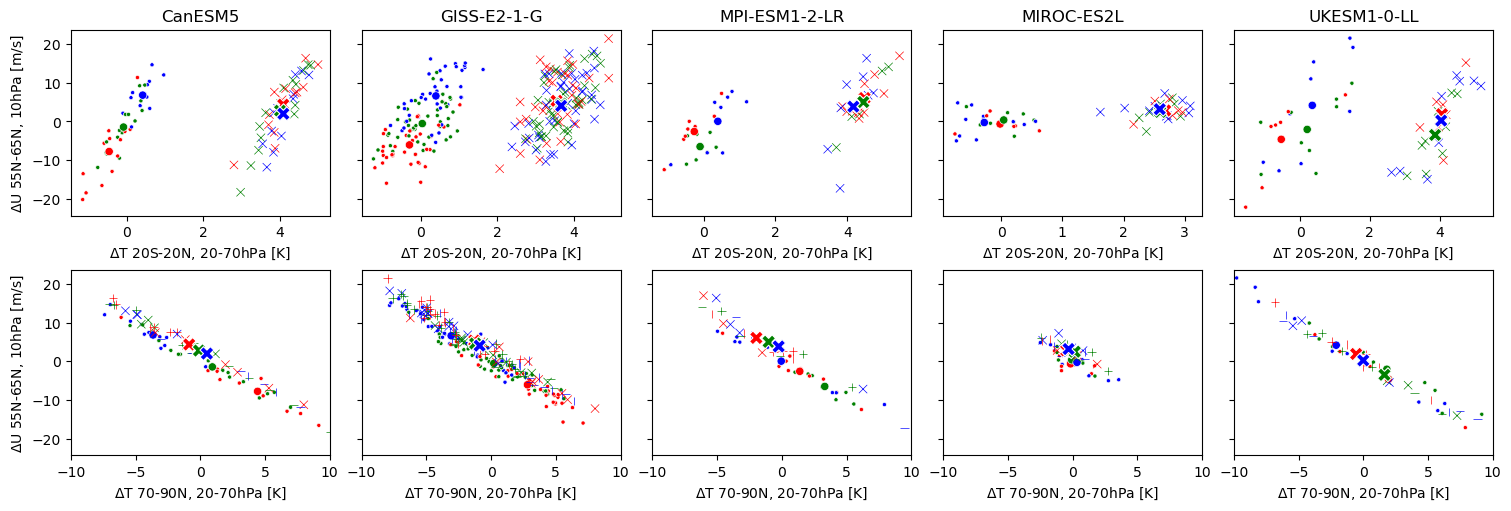

In [17]:
fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

markers = {'stayed': 'x', 'minus': 0, 'plus': '+', 'neutral': '|'}
for i, model in enumerate(models):
    c = sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='.', ax=axs[0, i], legend=False)
    c = sns.scatterplot(df_pi_control.loc[model].drop('year', axis=1).groupby('nao_flag').mean(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'],  ax=axs[0, i], legend=False)
    e = sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag_picontrol', palette=['red', 'green', 'blue'], marker='x', ax=axs[0, i], legend=False)
    e = sns.scatterplot(df_volc.loc[model].drop('change direction', axis=1).groupby('nao_flag_picontrol').mean(), x='deltaT_tropics', y='deltaU', hue='nao_flag_picontrol', palette=['red', 'green', 'blue'], marker='X', s=100, ax=axs[0, i], legend=False)
    # d = sns.scatterplot(df_volc_clim.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='+', ax=axs[0, i], legend=False)

    axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
    sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='.', ax=axs[1, i], legend=False)
    sns.scatterplot(df_pi_control.loc[model].drop('year', axis=1).groupby('nao_flag').mean(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag_picontrol', palette=['red', 'green', 'blue'], style="change direction", markers=markers, ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].drop('change direction', axis=1).groupby('nao_flag_picontrol').mean(), x='deltaT_polar', y='deltaU', hue='nao_flag_picontrol', palette=['red', 'green', 'blue'], marker='X', s=100, ax=axs[1, i], legend=False)
    # sns.scatterplot(df_volc_clim.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='+', ax=axs[1, i], legend=False)
    axs[1,i].set_xlim(-10,10)
    axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

    axs[0,i].set_title(model)
axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
axs[1,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')

plt.savefig(plotdir + 'volcVSpiControl_individualmodels_piControlFlags.png', dpi=200)

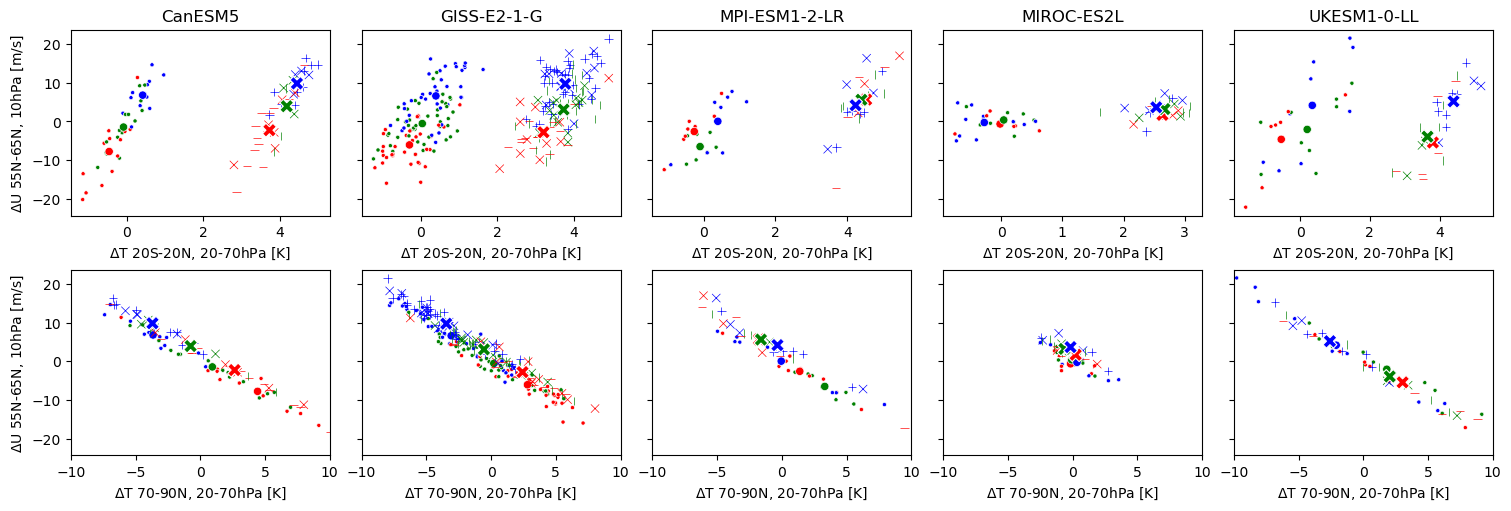

In [18]:
fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

markers = {'stayed': 'x', 'minus': 0, 'plus': '+', 'neutral': '|'}
for i, model in enumerate(models):
    c = sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='.', ax=axs[0, i], legend=False)
    c = sns.scatterplot(df_pi_control.loc[model].drop('year', axis=1).groupby('nao_flag').mean(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'],  ax=axs[0, i], legend=False)
    e = sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], style="change direction", markers=markers, ax=axs[0, i], legend=False)
    e = sns.scatterplot(df_volc.loc[model].drop('change direction', axis=1).groupby('nao_flag').mean(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='X', s=100, ax=axs[0, i], legend=False)
    # d = sns.scatterplot(df_volc_clim.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='+', ax=axs[0, i], legend=False)

    axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
    sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='.', ax=axs[1, i], legend=False)
    sns.scatterplot(df_pi_control.loc[model].drop('year', axis=1).groupby('nao_flag').mean(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], style="change direction", markers=markers, ax=axs[1, i], legend=False)
    sns.scatterplot(df_volc.loc[model].drop('change direction', axis=1).groupby('nao_flag').mean(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='X', s=100, ax=axs[1, i], legend=False)
    # sns.scatterplot(df_volc_clim.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='nao_flag', palette=['red', 'green', 'blue'], marker='+', ax=axs[1, i], legend=False)
    axs[1,i].set_xlim(-10,10)
    axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

    axs[0,i].set_title(model)
axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
axs[1,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')

plt.savefig(plotdir + 'volcVSpiControl_individualmodels_all.png', dpi=200)

In [19]:
df_volc.reset_index().to_csv('/home/kperny/VolMIP_stratosphere/tab/ta_ua_vulcan.csv')#.loc[model].drop('change direction', axis=1).groupby('change flag').mean()

In [20]:
# fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

# for i, model in enumerate(models):
#     c = sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='NAO piControl', palette=['red', 'green', 'blue'], ax=axs[0, i], legend=False)
#     d = sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='change flag', marker='x', palette={-1: 'red', 0: 'green', 1: 'blue', 2: 'orange', 3: 'lightseagreen', 4: 'magenta', -4: 'violet', -2: 'lightblue', -3: 'moccasin'}, ax=axs[0, i], legend=False)

#     axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
#     sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='NAO piControl', palette=['red', 'green', 'blue'], ax=axs[1, i], legend=False)
#     sns.scatterplot(df_volc.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='change flag', marker='x', ax=axs[1, i], palette={-1: 'red', 0: 'green', 1: 'blue', 2: 'orange', 3: 'lightseagreen', 4: 'magenta', -4: 'violet', -2: 'lightblue', -3: 'moccasin'}, legend=False)
#     axs[1,i].set_xlim(-10,10)
#     axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

#     axs[0,i].set_title(model)
# axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
# axs[1,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')

# plt.savefig(plotdir + 'volcVSpiControl_individualmodels_flagchange.png', dpi=200)

In [21]:
# fig, axs = plt.subplots(2,5, figsize=(15,5), sharey=True, layout='constrained')

# for i, model in enumerate(models):
#     c = sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_tropics', y='deltaU', hue='NAO piControl', palette=['red', 'green', 'blue'], ax=axs[0, i], legend=False)
#     d = sns.scatterplot(df_volc.loc[model].drop('change direction', axis=1).groupby('change flag').mean().reset_index(), x='deltaT_tropics', y='deltaU', hue='change flag', marker='x', palette={-1: 'red', 0: 'green', 1: 'blue', 2: 'orange', 3: 'lightseagreen', 4: 'magenta', -4: 'violet', -2: 'lightblue', -3: 'moccasin'}, ax=axs[0, i], legend=False)

#     axs[0,i].set_xlabel('$\Delta$T 20S-20N, 20-70hPa [K]')
#     sns.scatterplot(df_pi_control.loc[model].reset_index(), x='deltaT_polar', y='deltaU', hue='NAO piControl', palette=['red', 'green', 'blue'], ax=axs[1, i], legend=False)
#     sns.scatterplot(df_volc.loc[model].drop('change direction', axis=1).groupby('change flag').mean().reset_index(), x='deltaT_polar', y='deltaU', hue='change flag', marker='x', ax=axs[1, i], palette={-1: 'red', 0: 'green', 1: 'blue', 2: 'orange', 3: 'lightseagreen', 4: 'magenta', -4: 'violet', -2: 'lightblue', -3: 'moccasin'}, legend=False)
#     axs[1,i].set_xlim(-10,10)
#     axs[1,i].set_xlabel('$\Delta$T 70-90N, 20-70hPa [K]')

#     axs[0,i].set_title(model)
# axs[0,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')
# axs[1,0].set_ylabel('$\Delta$U 55N-65N, 10hPa [m/s]')

# plt.savefig(plotdir + 'volcVSpiControl_individualmodels_flagchange_mean.png', dpi=200)

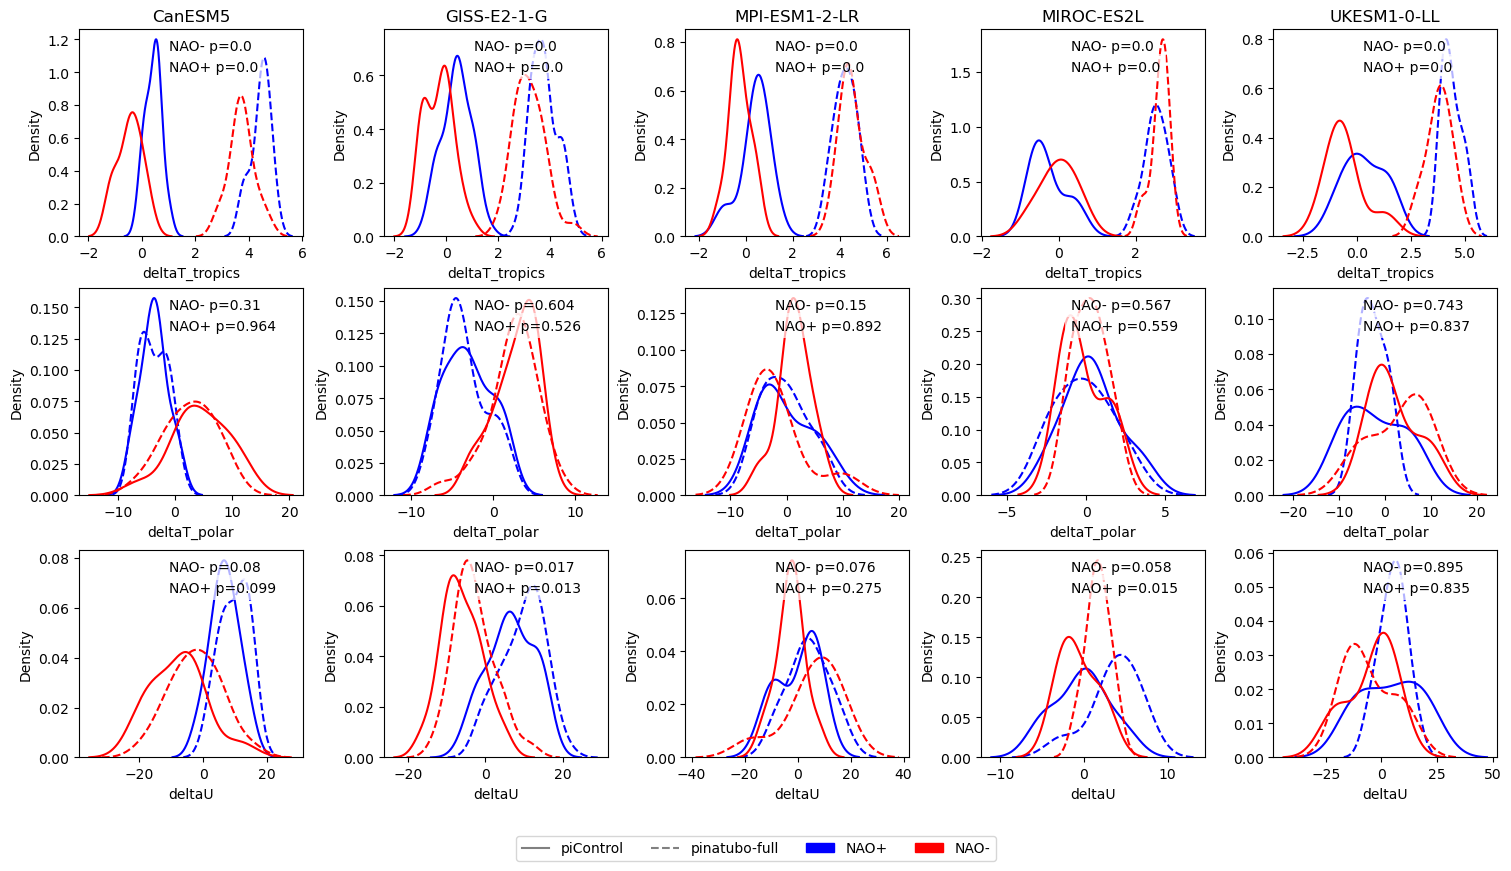

In [22]:
fig, axs = plt.subplots(3,5, figsize=(15,8), layout='constrained')


for i, model in enumerate(models):
    posnao_pi = df_pi_control.where(df_pi_control.nao_flag == 1).dropna().loc[model]
    negnao_pi = df_pi_control.where(df_pi_control.nao_flag == -1).dropna().loc[model]

    posnao_volc = df_volc.where(df_volc.nao_flag == 1).dropna().loc[model]
    negnao_volc = df_volc.where(df_volc.nao_flag == -1).dropna().loc[model]

    sns.kdeplot(posnao_pi, x='deltaT_tropics', color='blue', ax=axs[0, i])
    sns.kdeplot(posnao_volc, x='deltaT_tropics',color='blue', linestyle='--', ax=axs[0, i])
    sns.kdeplot(negnao_pi, x='deltaT_tropics', color='red', ax=axs[0, i])
    sns.kdeplot(negnao_volc, x='deltaT_tropics', color='red', linestyle='--', ax=axs[0, i])

    sns.kdeplot(posnao_pi, x='deltaT_polar', color='blue', ax=axs[1, i])
    sns.kdeplot(posnao_volc, x='deltaT_polar',color='blue', linestyle='--', ax=axs[1, i])
    sns.kdeplot(negnao_pi, x='deltaT_polar', color='red', ax=axs[1, i])
    sns.kdeplot(negnao_volc, x='deltaT_polar', color='red', linestyle='--', ax=axs[1, i])

    sns.kdeplot(posnao_pi, x='deltaU', color='blue', ax=axs[2, i])
    sns.kdeplot(posnao_volc, x='deltaU',color='blue', linestyle='--', ax=axs[2, i])
    sns.kdeplot(negnao_pi, x='deltaU', color='red', ax=axs[2, i])
    sns.kdeplot(negnao_volc, x='deltaU', color='red', linestyle='--', ax=axs[2, i])
   
    props = dict(facecolor='white', alpha=0.7, edgecolor='none')
    axs[0,i].text(0.4, 0.9, 'NAO- p=' + str(stats.ttest_ind(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values, equal_var=False)[1].round(3)), transform=axs[0,i].transAxes, bbox=props)
    axs[0,i].text(0.4, 0.8, 'NAO+ p=' + str(stats.ttest_ind(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values, equal_var=False)[1].round(3)), transform=axs[0,i].transAxes, bbox=props)
    axs[1,i].text(0.4, 0.9, 'NAO- p=' + str(stats.ttest_ind(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values, equal_var=False)[1].round(3)), transform=axs[1,i].transAxes, bbox=props)
    axs[1,i].text(0.4, 0.8, 'NAO+ p=' + str(stats.ttest_ind(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values, equal_var=False)[1].round(3)), transform=axs[1,i].transAxes, bbox=props)
    axs[2,i].text(0.4, 0.9, 'NAO- p=' + str(stats.ttest_ind(negnao_pi.deltaU.values , negnao_volc.deltaU.values, equal_var=False)[1].round(3)), transform=axs[2,i].transAxes, bbox=props)
    axs[2,i].text(0.4, 0.8, 'NAO+ p=' + str(stats.ttest_ind(posnao_pi.deltaU.values , posnao_volc.deltaU.values, equal_var=False)[1].round(3)), transform=axs[2,i].transAxes, bbox=props)

    axs[0,i].set_title(model)

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='piControl', color='grey')
volc = Line2D([0], [0], label='pinatubo-full', color='grey', linestyle='--')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=4)
plt.savefig('/home/kperny/VolMIP_stratosphere/plots/distribution_comparison.png', dpi=200)

In [ ]:
df_pi_control.where()

nao_flag  enso_flag        year  deltaT_tropics  \
model       realization                                                    
CanESM5     r15i1p2f1           1          0  5965-02-01        0.594833   
            r5i1p2f1           -1          0  5643-02-01        0.094850   
            r29i1p2f1           0         -1  6331-02-01        0.222195   
            r16i1p2f1          -1          1  5992-02-01       -0.438830   
            r6i1p2f1            0          0  5787-02-01       -0.231004   
...                           ...        ...         ...             ...   
UKESM1-0-LL r11i1p1f2           1         -1  3123-02-01        1.423468   
            r9i1p1f2            1          0  3036-02-01        0.389667   
            r25i1p1f2           0          0  3162-02-01       -1.127106   
            r5i1p1f2            1          1  3099-02-01        1.515266   
            r3i1p1f2            0          1  3050-02-01        0.266944   

                         deltaT_polar     deltaU  NAO piControl  
model       realization                                          
CanESM5     r15i1p2f1       -5.402757  10.351215              1  
            r5i1p2f1         1.320145  -2.042218             -1  
            r29i1p2f1        0.608538   0.129088              0  
            r16i1p2f1        4.690070  -4.428785             -1  
            r6i1p2f1         2.258429  -4.071079              0  
...                               ...        ...            ...  
UKESM1-0-LL r11i1p1f2       -2.407708   2.605983              1  
            r9i1p1f2        -8.105598  15.376194              1  
            r25i1p1f2        0.778790  -0.200168              0  
            r5i1p1f2        -8.358116  19.120193              1  
            r3i1p1f2         5.538252  -7.498881              0  

[236 rows x 7 columns]

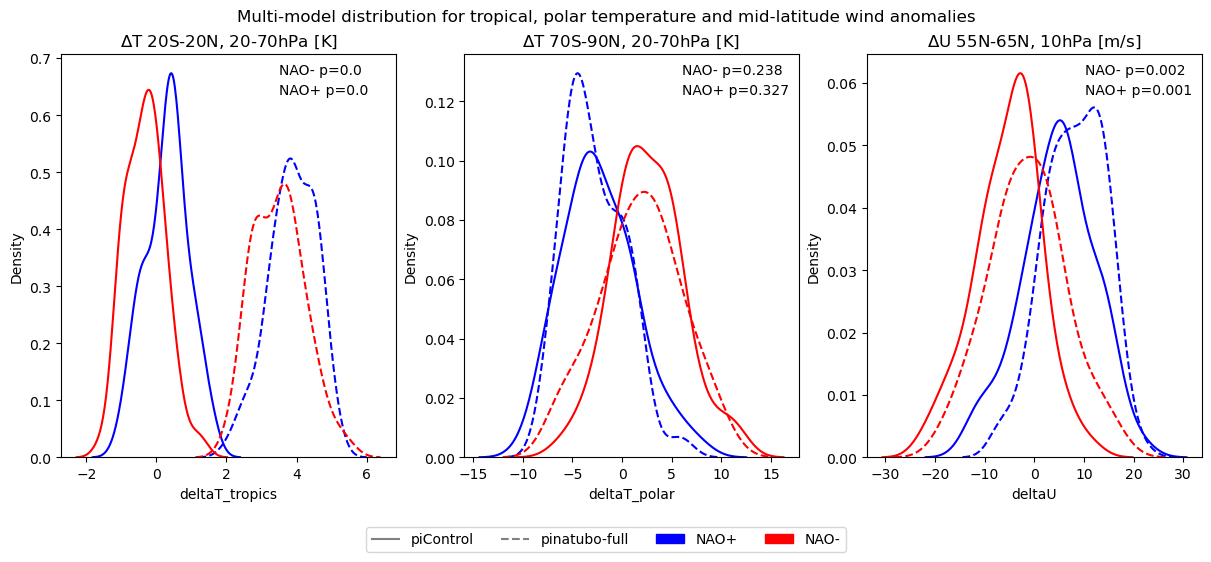

In [30]:
fig, axs = plt.subplots(1,3, figsize=(12,5), layout='constrained')



posnao_pi = df_pi_control.where(df_pi_control.nao_flag == 1).dropna()
negnao_pi = df_pi_control.where(df_pi_control.nao_flag == -1).dropna()

posnao_volc = df_volc.where(df_volc.nao_flag == 1).dropna()
negnao_volc = df_volc.where(df_volc.nao_flag == -1).dropna()

sns.kdeplot(posnao_pi, x='deltaT_tropics', color='blue', ax=axs[0])
sns.kdeplot(posnao_volc, x='deltaT_tropics',color='blue', linestyle='--', ax=axs[0])
sns.kdeplot(negnao_pi, x='deltaT_tropics', color='red', ax=axs[0])
sns.kdeplot(negnao_volc, x='deltaT_tropics', color='red', linestyle='--', ax=axs[0])

sns.kdeplot(posnao_pi, x='deltaT_polar', color='blue', ax=axs[1])
sns.kdeplot(posnao_volc, x='deltaT_polar',color='blue', linestyle='--', ax=axs[1])
sns.kdeplot(negnao_pi, x='deltaT_polar', color='red', ax=axs[1])
sns.kdeplot(negnao_volc, x='deltaT_polar', color='red', linestyle='--', ax=axs[1])

sns.kdeplot(posnao_pi, x='deltaU', color='blue', ax=axs[2])
sns.kdeplot(posnao_volc, x='deltaU',color='blue', linestyle='--', ax=axs[2])
sns.kdeplot(negnao_pi, x='deltaU', color='red', ax=axs[2])
sns.kdeplot(negnao_volc, x='deltaU', color='red', linestyle='--', ax=axs[2])
   
props = dict(facecolor='white', alpha=0.7, edgecolor='none')
axs[0].text(0.65, 0.95, 'NAO- p=' + str(stats.ttest_ind(negnao_pi.deltaT_tropics.values , negnao_volc.deltaT_tropics.values, equal_var=False)[1].round(3)), transform=axs[0].transAxes, bbox=props)
axs[0].text(0.65, 0.9, 'NAO+ p=' + str(stats.ttest_ind(posnao_pi.deltaT_tropics.values , posnao_volc.deltaT_tropics.values, equal_var=False)[1].round(3)), transform=axs[0].transAxes, bbox=props)
axs[1].text(0.65, 0.95, 'NAO- p=' + str(stats.ttest_ind(negnao_pi.deltaT_polar.values , negnao_volc.deltaT_polar.values, equal_var=False)[1].round(3)), transform=axs[1].transAxes, bbox=props)
axs[1].text(0.65, 0.9, 'NAO+ p=' + str(stats.ttest_ind(posnao_pi.deltaT_polar.values , posnao_volc.deltaT_polar.values, equal_var=False)[1].round(3)), transform=axs[1].transAxes, bbox=props)
axs[2].text(0.65, 0.95, 'NAO- p=' + str(stats.ttest_ind(negnao_pi.deltaU.values , negnao_volc.deltaU.values, equal_var=False)[1].round(3)), transform=axs[2].transAxes, bbox=props)
axs[2].text(0.65, 0.9, 'NAO+ p=' + str(stats.ttest_ind(posnao_pi.deltaU.values , posnao_volc.deltaU.values, equal_var=False)[1].round(3)), transform=axs[2].transAxes, bbox=props)

axs[0].set_title('$\Delta$T 20S-20N, 20-70hPa [K]')
axs[1].set_title('$\Delta$T 70S-90N, 20-70hPa [K]')
axs[2].set_title('$\Delta$U 55N-65N, 10hPa [m/s]')

from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
piControl = Line2D([0], [0], label='piControl', color='grey')
volc = Line2D([0], [0], label='pinatubo-full', color='grey', linestyle='--')
ponao = mpatches.Patch(color='blue', label='NAO+')
negnao = mpatches.Patch(color='red', label='NAO-')

fig.legend(handles= [piControl, volc, ponao, negnao], loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=4)
plt.suptitle('Multi-model distribution for tropical, polar temperature and mid-latitude wind anomalies')
plt.savefig('/home/kperny/VolMIP_stratosphere/plots/distribution_multimodel.png', dpi=200)